Name: Shambhavi Rai 
 
Section: B3 

Batch: B2 

Roll No.: 22

## SI LAB PROJECT

### Regression: Electricity Consumption Prediction
**Dataset:** Power Consumption of Tetouan City (Kaggle)

**Link:** https://www.kaggle.com/datasets/ruchikakumbhar/power-consumption-prediction-dataset


**Aim:** To analyse the power consumption data of Tetouan City using statistics and visualization, and to build regression models that predict electricity consumption.

**Target variable:** Total_Consumption & Zone 1, Zone 2, Zone 3 power consumption.

##### 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import joblib
from scipy import stats
from scipy.stats import pearsonr, spearmanr, chi2_contingency, skew, norm, uniform, binom

##### 2. Loading the Dataset

In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub
path = kagglehub.dataset_download("ruchikakumbhar/power-consumption-prediction-dataset")
csv_files = glob.glob(path + "/**/*.csv", recursive=True)
print("CSV files found:", csv_files)

df = pd.read_csv(csv_files[0])
print("First 5 rows:")
df.head()

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CSV files found: ['C:\\Users\\user\\.cache\\kagglehub\\datasets\\ruchikakumbhar\\power-consumption-prediction-dataset\\versions\\1\\power consumption.csv']
First 5 rows:


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1,Zone 2,Zone 3
0,01-01-2017 00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,01-01-2017 00:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,01-01-2017 00:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,01-01-2017 00:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,01-01-2017 00:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [4]:
print("Last 5 rows:")
df.tail()

Last 5 rows:


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1,Zone 2,Zone 3
52411,12/30/2017 23:10,7.010,72.4,0.080,0.040,0.096,31160.45627,26857.31820,14780.31212
52412,12/30/2017 23:20,6.947,72.6,0.082,0.051,0.093,30430.41825,26124.57809,14428.81152
52413,12/30/2017 23:30,6.900,72.8,0.086,0.084,0.074,29590.87452,25277.69254,13806.48259
52414,12/30/2017 23:40,6.758,73.0,0.080,0.066,0.089,28958.17490,24692.23688,13512.60504
52415,12/30/2017 23:50,6.580,74.1,0.081,0.062,0.111,28349.80989,24055.23167,13345.49820


Rename columns for later use

In [5]:
new_names = {}
for col in df.columns:
    key = "".join(ch for ch in col.lower() if ch.isalnum())
    if "zone1" in key:
        new_names[col] = "Zone1"
    elif "zone2" in key:
        new_names[col] = "Zone2"
    elif "zone3" in key:
        new_names[col] = "Zone3"
    elif "generaldiffuse" in key:
        new_names[col] = "GeneralDiffuseFlows"
    elif "diffuse" in key:
        new_names[col] = "DiffuseFlows"
    elif "wind" in key:
        new_names[col] = "WindSpeed"
    elif "temp" in key:
        new_names[col] = "Temperature"
    elif "humid" in key:
        new_names[col] = "Humidity"
    elif "date" in key or "time" in key:
        new_names[col] = "DateTime"

df.rename(columns=new_names, inplace=True)
print(df.columns.tolist())

['DateTime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'Zone1', 'Zone2', 'Zone3']


##### 3. Understanding the Data

In [6]:
print("Original Data Shape: ",df.shape)
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])

Original Data Shape:  (52416, 9)
Rows: 52416
Columns: 9


In [7]:
print("Column name:")
df.columns

Column name:


Index(['DateTime', 'Temperature', 'Humidity', 'WindSpeed',
       'GeneralDiffuseFlows', 'DiffuseFlows', 'Zone1', 'Zone2', 'Zone3'],
      dtype='object')

In [8]:
print("Datatypes:")
df.dtypes

Datatypes:


DateTime                object
Temperature            float64
Humidity               float64
WindSpeed              float64
GeneralDiffuseFlows    float64
DiffuseFlows           float64
Zone1                  float64
Zone2                  float64
Zone3                  float64
dtype: object

In [9]:
print("Dataset information: ")
df.info()

Dataset information: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DateTime             52416 non-null  object 
 1   Temperature          52416 non-null  float64
 2   Humidity             52416 non-null  float64
 3   WindSpeed            52416 non-null  float64
 4   GeneralDiffuseFlows  52416 non-null  float64
 5   DiffuseFlows         52416 non-null  float64
 6   Zone1                52416 non-null  float64
 7   Zone2                52416 non-null  float64
 8   Zone3                52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB


In [10]:
print("Statistical summary:")
df.describe(include='all')

Statistical summary:


,DateTime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,Zone1,Zone2,Zone3
count,52416,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
unique,52416,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,12/30/2017 21:10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,NaN,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,NaN,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,NaN,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,NaN,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,NaN,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420


In [11]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
DateTime               0
Temperature            0
Humidity               0
WindSpeed              0
GeneralDiffuseFlows    0
DiffuseFlows           0
Zone1                  0
Zone2                  0
Zone3                  0
dtype: int64

Duplicate rows: 0


##### 4. Feature Extraction 

In [12]:
needed = ["DateTime", "Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows", "Zone1", "Zone2", "Zone3"]
df_eda = df[needed].copy()

df_eda["DateTime"] = pd.to_datetime(df_eda["DateTime"].astype(str).str.replace("-", "/"), format="mixed")
for col in needed[1:]:
    df_eda[col] = pd.to_numeric(df_eda[col], errors="coerce")
df_eda = df_eda.dropna().reset_index(drop=True)

df_eda["Hour"] = df_eda["DateTime"].dt.hour
df_eda["Month"] = df_eda["DateTime"].dt.month
df_eda["DayOfMonth"] = df_eda["DateTime"].dt.day
df_eda["DayOfWeek"] = df_eda["DateTime"].dt.day_name()
df_eda["Weekend"] = df_eda["DayOfWeek"].isin(["Saturday", "Sunday"]).astype(int)

df_eda["Total_Consumption"] = df_eda["Zone1"] + df_eda["Zone2"] + df_eda["Zone3"]
df_eda.head()

,DateTime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,Zone1,Zone2,Zone3,Hour,Month,DayOfMonth,DayOfWeek,Weekend,Total_Consumption
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,0,1,1,Sunday,1,70425.53544
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,0,1,1,Sunday,1,69320.84387
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,0,1,1,Sunday,1,67803.22193
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,0,1,1,Sunday,1,65489.23209
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,0,1,1,Sunday,1,63650.44627


##### 5. Descriptive Statistics of the Target

In [13]:
x = df_eda["Total_Consumption"]

print("Mean:", x.mean())
print("Median:", x.median())
print("Mode:", x.mode()[0])
print("Variance:", x.var())
print("Standard Deviation:", x.std())
print("Range:", x.max() - x.min())
Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)
print("IQR:", Q3 - Q1)

Mean: 71222.88586428425
Median: 69788.79094
Mode: 36785.039739
Variance: 293887213.52827233
Standard Deviation: 17143.138963686677
Range: 97423.106211
IQR: 27250.09766999999


##### 6. Exploratory Data Analysis and Visualization

In [14]:
# Numerical Columns
numerical_cols = df_eda.select_dtypes(include=np.number).columns
print("Numerical Columns:")
print(numerical_cols.tolist())

# Categorical Columns
categorical_cols = df_eda.select_dtypes(include='object').columns
print("\nCategorical Columns:")
print(categorical_cols.tolist())

Numerical Columns:
['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'Zone1', 'Zone2', 'Zone3', 'Hour', 'Month', 'DayOfMonth', 'Weekend', 'Total_Consumption']

Categorical Columns:
['DayOfWeek']


6.1 Distribution of Total Consumption

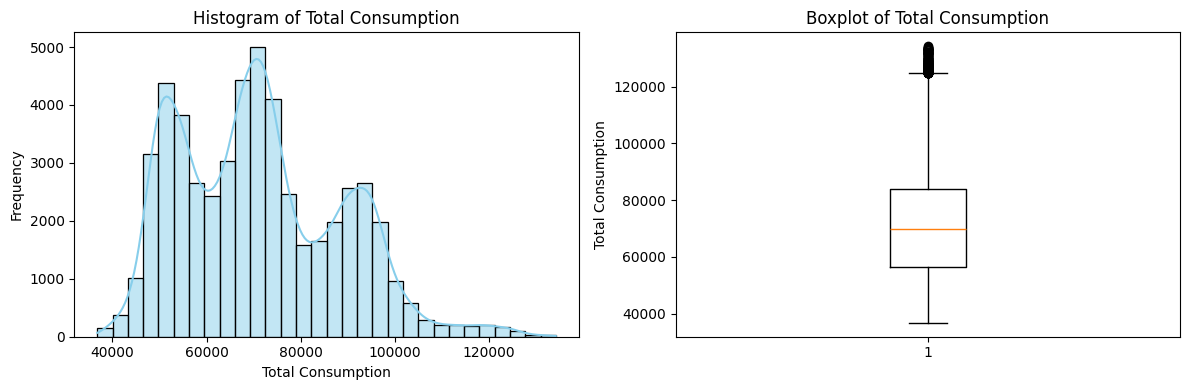

In [15]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
sns.histplot(df_eda["Total_Consumption"], bins=30, kde=True, color="skyblue")
plt.title("Histogram of Total Consumption")
plt.xlabel("Total Consumption")
plt.ylabel("Frequency")

plt.subplot(1,2,2)
plt.boxplot(df_eda["Total_Consumption"])
plt.title("Boxplot of Total Consumption")
plt.ylabel("Total Consumption")

plt.tight_layout()
plt.show()

6.2 Consumption by Hour, Month and Day of Week

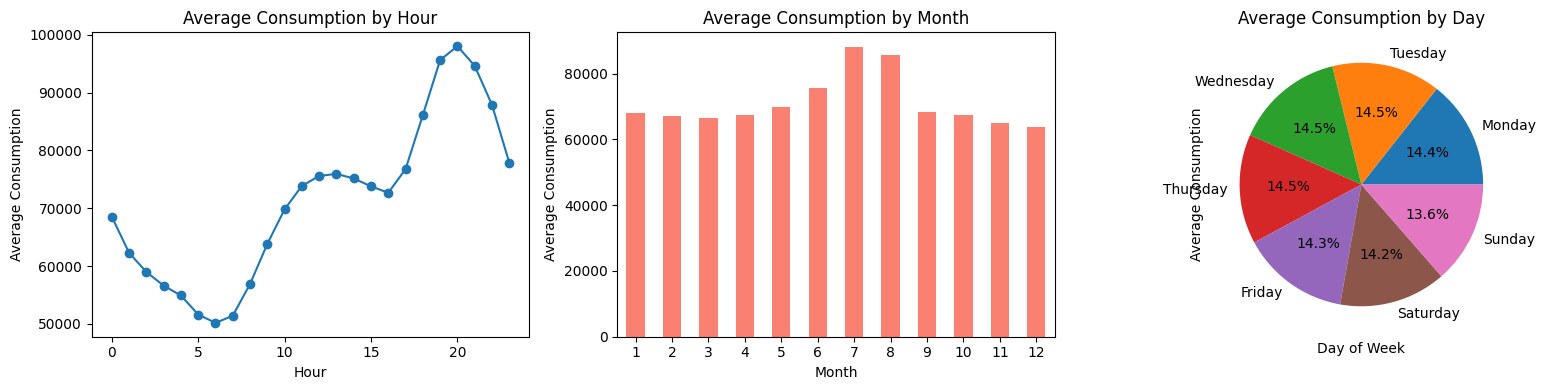

In [16]:
plt.figure(figsize=(16,4))

plt.subplot(1,3,1)
df_eda.groupby("Hour")["Total_Consumption"].mean().plot(kind="line", marker="o")
plt.title("Average Consumption by Hour")
plt.xlabel("Hour")
plt.ylabel("Average Consumption")

plt.subplot(1,3,2)
df_eda.groupby("Month")["Total_Consumption"].mean().plot(kind="bar", color="salmon")
plt.title("Average Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Consumption")
plt.xticks(rotation=0)

plt.subplot(1,3,3)
days = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df_eda.groupby("DayOfWeek")["Total_Consumption"].mean().reindex(days).plot(kind="pie", autopct='%1.1f%%')
plt.title("Average Consumption by Day")
plt.xlabel("Day of Week")
plt.ylabel("Average Consumption")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

6.2b Zone-wise Consumption

In [17]:
zones = ["Zone1", "Zone2", "Zone3", "Total_Consumption"]
print(df_eda[zones].describe().round(2))

          Zone1     Zone2     Zone3  Total_Consumption
count  52416.00  52416.00  52416.00           52416.00
mean   32344.97  21042.51  17835.41           71222.89
std     7130.56   5201.47   6622.17           17143.14
min    13895.70   8560.08   5935.17           36785.04
25%    26310.67  16980.77  13129.33           56499.07
50%    32265.92  20823.17  16415.12           69788.79
75%    37309.02  24713.72  21624.10           83749.17
max    52204.40  37408.86  47598.33          134208.15


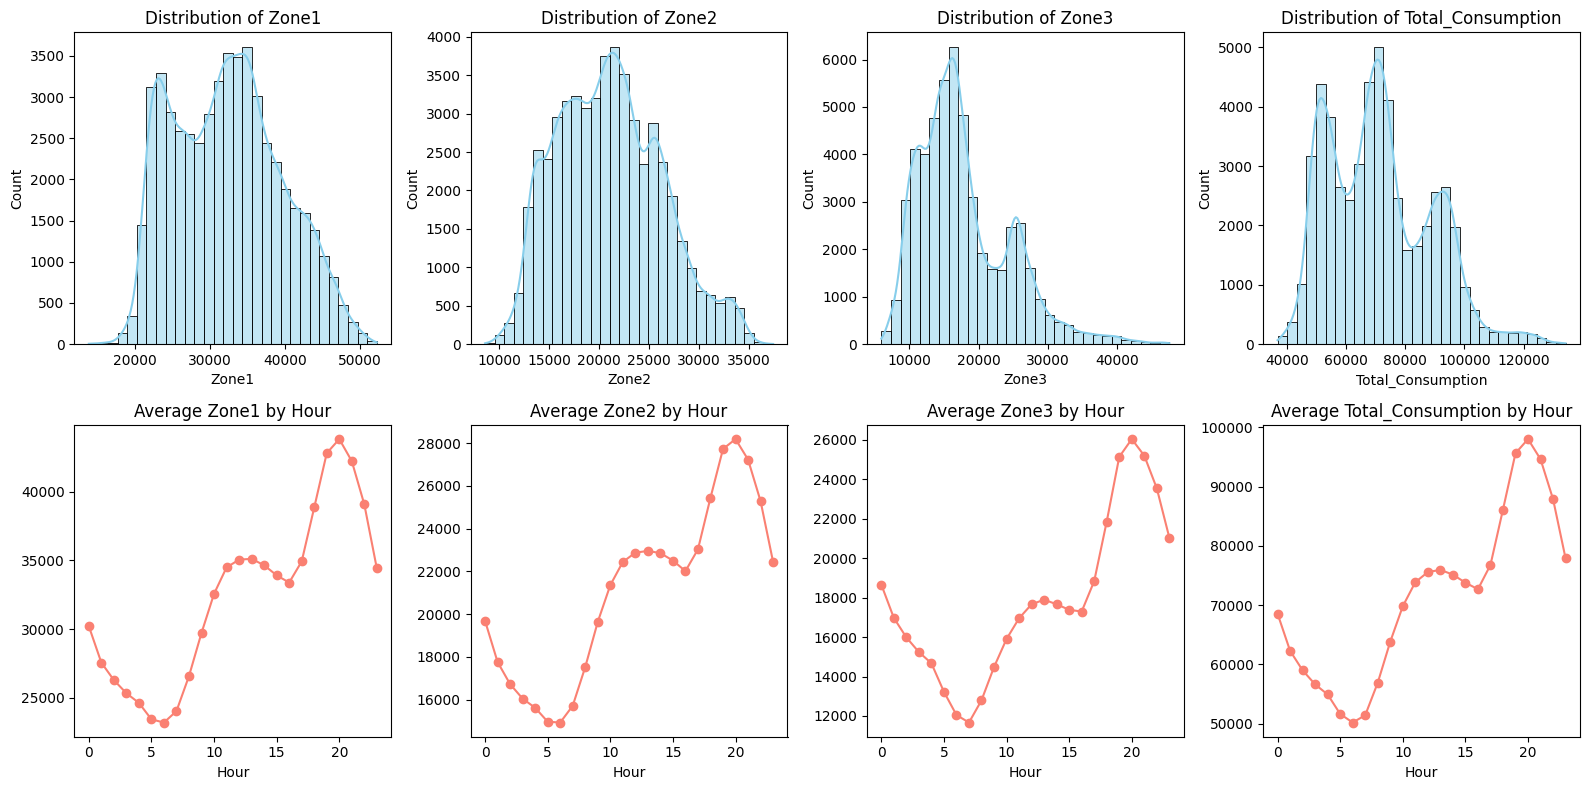

In [18]:
plt.figure(figsize=(16,8))

for i, col in enumerate(zones):
    plt.subplot(2,4,i+1)
    sns.histplot(df_eda[col], bins=30, kde=True, color="skyblue")
    plt.title("Distribution of " + col)
    plt.xlabel(col)

for i, col in enumerate(zones):
    plt.subplot(2,4,i+5)
    df_eda.groupby("Hour")[col].mean().plot(kind="line", marker="o", color="salmon")
    plt.title("Average " + col + " by Hour")
    plt.xlabel("Hour")

plt.tight_layout()
plt.show()

6.3 Weather Features vs Consumption

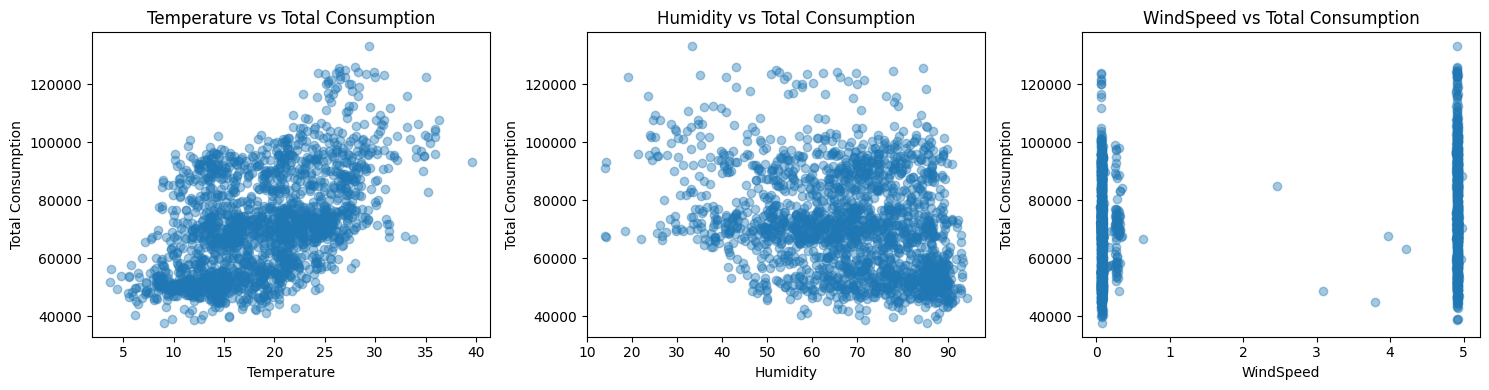

In [19]:
sample_plot = df_eda.sample(n=2000, random_state=42)

plt.figure(figsize=(15,4))
for i, col in enumerate(["Temperature", "Humidity", "WindSpeed"]):
    plt.subplot(1,3,i+1)
    plt.scatter(sample_plot[col], sample_plot["Total_Consumption"], alpha=0.4)
    plt.title(col + " vs Total Consumption")
    plt.xlabel(col)
    plt.ylabel("Total Consumption")
plt.tight_layout()
plt.show()

6.4 Correlation Heatmap

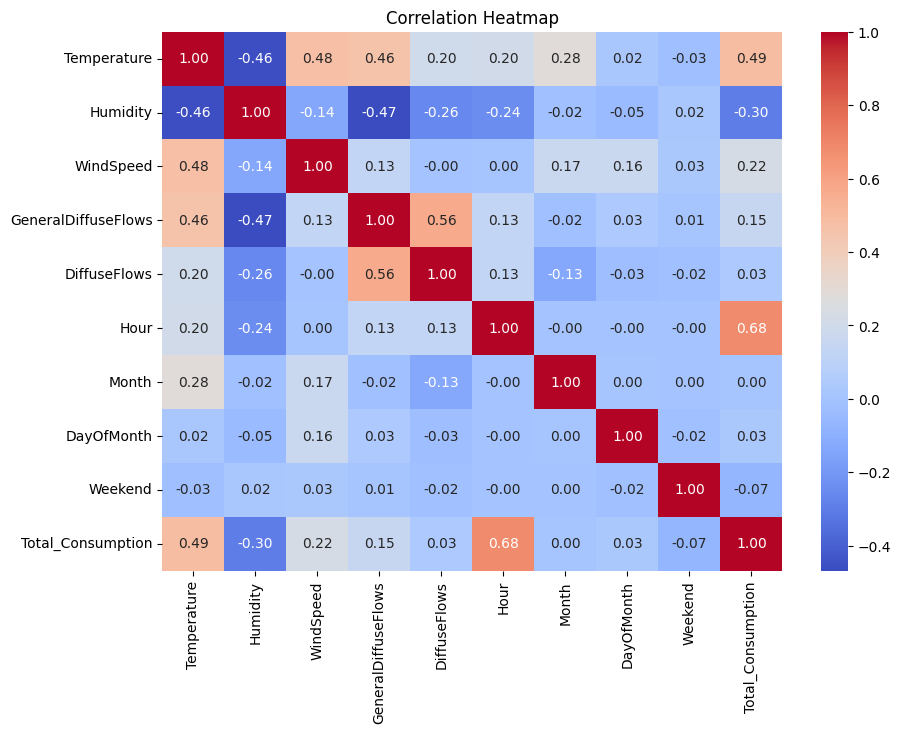

In [20]:
num_cols = ["Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows",
            "DiffuseFlows", "Hour", "Month", "DayOfMonth", "Weekend", "Total_Consumption"]

plt.figure(figsize=(10,7))
sns.heatmap(df_eda[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

##### 7. Probability Distributions

In [21]:
variables = ["Temperature", "Humidity", "WindSpeed", "Total_Consumption"]

for var in variables:
    value = skew(df_eda[var])
    print(var, ":", round(value, 3))
    if -0.5 <= value <= 0.5:
        print("Approximately Normal Distribution\n")
    else:
        print("Not Normally Distributed\n")

Temperature : 0.197
Approximately Normal Distribution

Humidity : -0.625
Not Normally Distributed

WindSpeed : 0.462
Approximately Normal Distribution

Total_Consumption : 0.519
Not Normally Distributed



Comparing Total Consumption with Normal, Uniform and (simulated) Binomial distributions.

In [22]:
data = df_eda["Total_Consumption"]

normal_data = np.random.normal(data.mean(), data.std(), len(data))
uniform_data = np.random.uniform(data.min(), data.max(), len(data))
binom_data = np.random.binomial(10, 0.5, len(data))

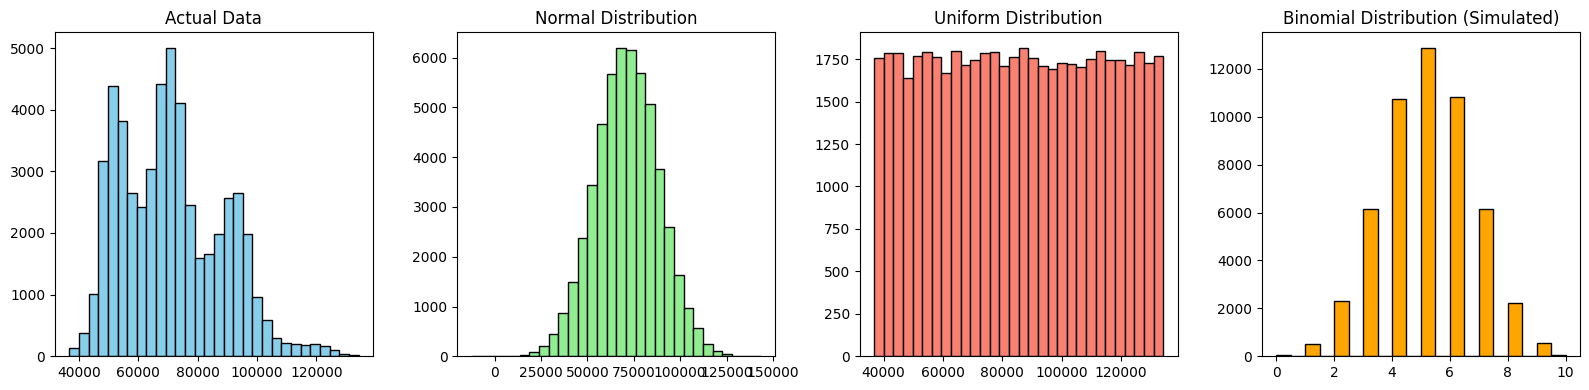

In [23]:
plt.figure(figsize=(16,4))

plt.subplot(1,4,1)
plt.hist(data, bins=30, edgecolor="black", color="skyblue")
plt.title("Actual Data")

plt.subplot(1,4,2)
plt.hist(normal_data, bins=30, edgecolor="black", color="lightgreen")
plt.title("Normal Distribution")

plt.subplot(1,4,3)
plt.hist(uniform_data, bins=30, edgecolor="black", color="salmon")
plt.title("Uniform Distribution")

plt.subplot(1,4,4)
plt.hist(binom_data, bins=20, edgecolor="black", color="orange")
plt.title("Binomial Distribution (Simulated)")

plt.tight_layout()
plt.show()

##### 8. Statistical Sampling

In [24]:
simple_sample = df_eda.sample(n=500, random_state=42)

k = 5
systematic_sample = df_eda.iloc[::k]

stratified_sample = df_eda.groupby("Month").sample(n=100, random_state=42)

clusters = np.random.choice(df_eda["DayOfWeek"].unique(), 2, replace=False)
cluster_sample = df_eda[df_eda["DayOfWeek"].isin(clusters)]

print("Clusters selected:", clusters)

Clusters selected: ['Saturday' 'Thursday']


In [25]:
def calculate_statistics(data):
    return {
        "Mean Consumption": data["Total_Consumption"].mean(),
        "Std Dev Consumption": data["Total_Consumption"].std(),
        "Mean Temperature": data["Temperature"].mean(),
        "Sample Size": len(data)
    }

comparisons = pd.DataFrame({
    "Population": calculate_statistics(df_eda),
    "Simple Random": calculate_statistics(simple_sample),
    "Systematic": calculate_statistics(systematic_sample),
    "Stratified": calculate_statistics(stratified_sample),
    "Cluster": calculate_statistics(cluster_sample)
})
comparisons

,Population,Simple Random,Systematic,Stratified,Cluster
Mean Consumption,71222.885864,71307.583539,71223.624829,71088.964040,71690.759262
Std Dev Consumption,17143.138964,17549.526470,17141.534822,16584.228603,17078.431577
Mean Temperature,18.810024,18.619902,18.808654,18.823286,18.723114
Sample Size,52416.000000,500.000000,10484.000000,1200.000000,14976.000000


##### 9. Central Limit Theorem and Sampling Distribution

In [26]:
population_mean = df_eda["Total_Consumption"].mean()
population_std = df_eda["Total_Consumption"].std()
print("Population Mean:", population_mean)
print("Population Std:", population_std)

Population Mean: 71222.88586428425
Population Std: 17143.138963686677


Sample size: 30 | Standard Error: 3129.895
Sample size: 50 | Standard Error: 2424.406
Sample size: 100 | Standard Error: 1714.314
Sample size: 200 | Standard Error: 1212.203


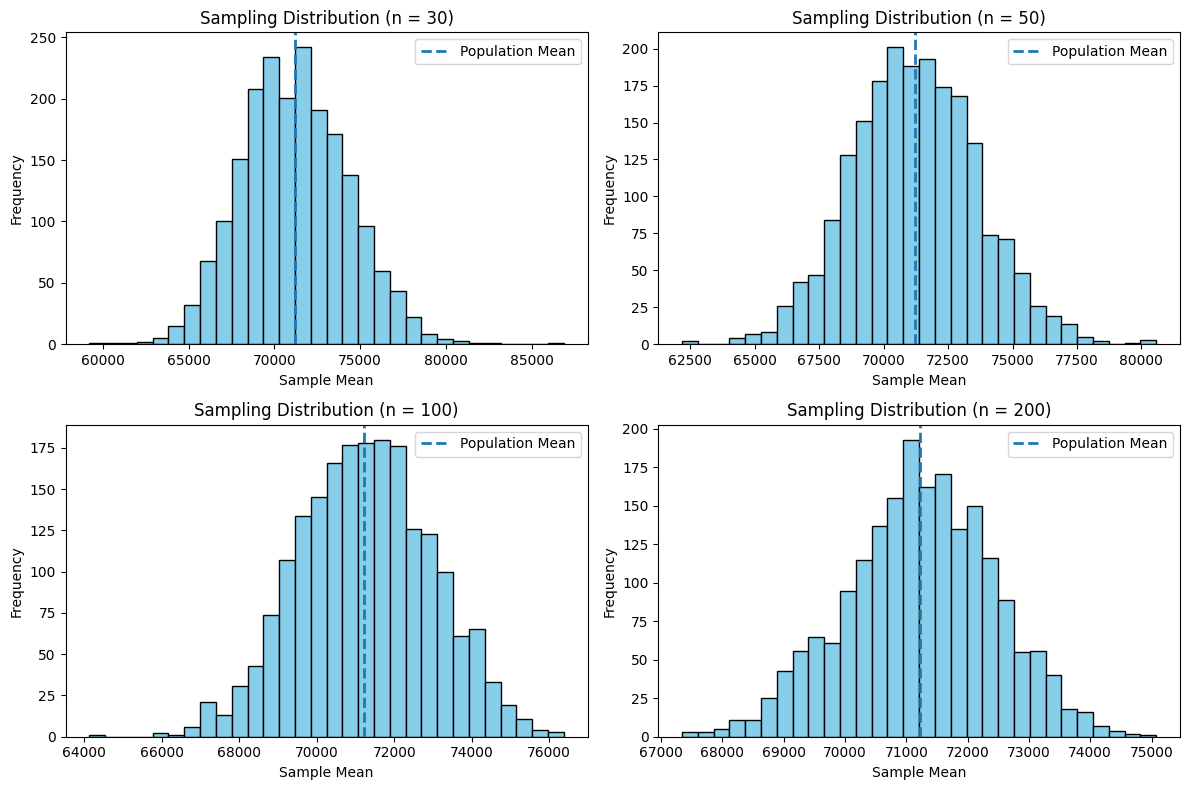

In [27]:
sample_sizes = [30, 50, 100, 200]
number_of_samples = 2000

plt.figure(figsize=(12, 8))

j = 1

for n in sample_sizes:
    sample_means = []

    for i in range(number_of_samples):
        sample = df_eda["Total_Consumption"].sample(
            n=n, random_state=i
        )
        sample_means.append(sample.mean())

    standard_error = population_std / np.sqrt(n)

    print("Sample size:", n, "| Standard Error:", round(standard_error,3))

    plt.subplot(2, 2, j)
    plt.hist(sample_means, bins=30, edgecolor="black", color="skyblue")
    plt.axvline(
        x=population_mean,
        linestyle="--",
        linewidth=2,
        label="Population Mean"
    )
    plt.title("Sampling Distribution (n = " + str(n) + ")")
    plt.xlabel("Sample Mean")
    plt.ylabel("Frequency")
    plt.legend()

    j += 1

plt.tight_layout()
plt.show()

As sample size increases, standard error decreases.

##### 10. Confidence Interval

A sample of 100 readings is used to estimate the population mean. CI = x̄ ± t(α/2) × s/√n

In [28]:
data = df_eda["Total_Consumption"].sample(n=100, random_state=42)

n = len(data)
sample_mean = np.mean(data)
sample_std = np.std(data, ddof=1)
confidence = 0.95

standard_error = sample_std / np.sqrt(n)
t_critical = stats.t.ppf((1 + confidence) / 2, n - 1)
margin_of_error = t_critical * standard_error

lower = sample_mean - margin_of_error
upper = sample_mean + margin_of_error

print("Sample Mean:", sample_mean)
print("Standard Error:", standard_error)
print("Margin of Error:", margin_of_error)
print("95% Confidence Interval:", "(", lower, ",", upper, ")")
print("Population Mean:", population_mean)

Sample Mean: 71729.15862001
Standard Error: 1668.0620793308954
Margin of Error: 3309.7970539771836
95% Confidence Interval: ( 68419.36156603282 , 75038.95567398718 )
Population Mean: 71222.88586428425


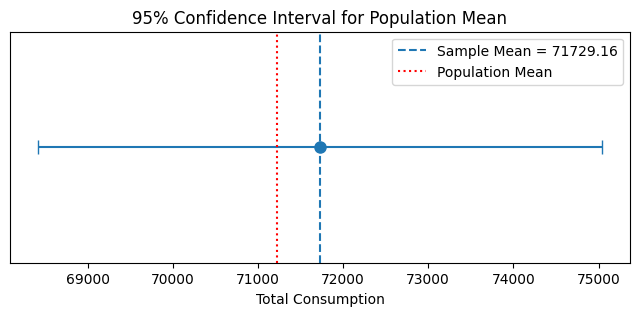

In [29]:
plt.figure(figsize=(8,3))
plt.errorbar(sample_mean, 1, xerr=margin_of_error, fmt="o", capsize=5, markersize=8)
plt.axvline(sample_mean, linestyle="--", label=f"Sample Mean = {sample_mean:.2f}")
plt.axvline(population_mean, linestyle=":", color="red", label="Population Mean")
plt.xlabel("Total Consumption")
plt.yticks([])
plt.title("95% Confidence Interval for Population Mean")
plt.legend()
plt.show()

##### 11. Hypothesis Testing

11.1 One-Sample t-Test

H0: μ = 70000  
H1: μ ≠ 70000

In [30]:
alpha = 0.05
t_stat, p_value = stats.ttest_1samp(data, popmean=70000)

print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

t-statistic: 1.03662725832339
p-value: 0.3024350067142635
Fail to reject the null hypothesis.


11.2 One-Sample Z-Test

Population standard deviation is known

In [31]:
mu = 70000
z_score = (sample_mean - mu) / (population_std / np.sqrt(n))
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_score)))

print("Z-score:", z_score)
print("p-value:", p_value_z)

if p_value_z < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Z-score: 1.0086592797694613
p-value: 0.3131380669586574
Fail to reject the null hypothesis.


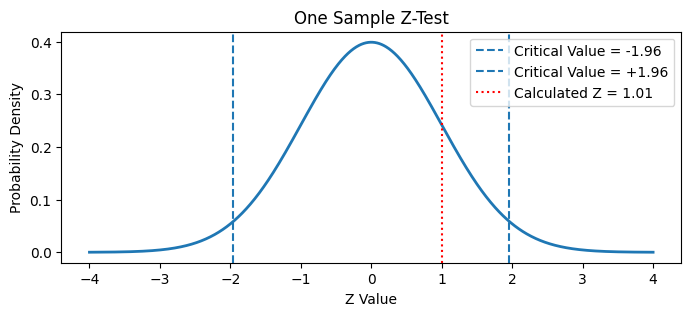

In [32]:
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

plt.figure(figsize=(8,3))
plt.plot(x, y, linewidth=2)
plt.axvline(-1.96, linestyle="--", label="Critical Value = -1.96")
plt.axvline(1.96, linestyle="--", label="Critical Value = +1.96")
plt.axvline(max(min(z_score, 4), -4), linestyle=":", color="red", label=f"Calculated Z = {z_score:.2f}")
plt.xlabel("Z Value")
plt.ylabel("Probability Density")
plt.title("One Sample Z-Test")
plt.legend()
plt.show()

11.3 Two-Sample t-Test (Weekday vs Weekend)

The two groups are independent because a reading belongs to either a weekday or a weekend.  
H0: μ(weekday) = μ(weekend)  
H1: μ(weekday) ≠ μ(weekend)

In [33]:
weekday = df_eda[df_eda["Weekend"] == 0]["Total_Consumption"]
weekend = df_eda[df_eda["Weekend"] == 1]["Total_Consumption"]

t_stat, p_value = stats.ttest_ind(weekday, weekend, equal_var=False)

print("Mean Weekday:", weekday.mean())
print("Mean Weekend:", weekend.mean())
print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < alpha:
    print("Reject H0: There is a significant difference.")
else:
    print("Fail to reject H0: No significant difference.")

Mean Weekday: 71999.1477632118
Mean Weekend: 69282.23111696541
t-statistic: 16.375460999523266
p-value: 5.52409580408053e-60
Reject H0: There is a significant difference.


11.4 Paired t-Test (Zone 1 vs Zone 2)

The readings of both zones are taken at the same time, so the groups are dependent.  
H0: mean difference = 0  
H1: mean difference ≠ 0

In [34]:
t_stat, p_value = stats.ttest_rel(df_eda["Zone1"], df_eda["Zone2"])

print("Mean Zone 1:", df_eda["Zone1"].mean())
print("Mean Zone 2:", df_eda["Zone2"].mean())
print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Mean Zone 1: 32344.970563585928
Mean Zone 2: 21042.509082321638
t-statistic: 646.9805484401104
p-value: 0.0
Reject H0


11.5 One-Way ANOVA (Time of Day)

H0: μ(Night) = μ(Morning) = μ(Afternoon) = μ(Evening)  
H1: At least one mean is different

In [35]:
night = df_eda[df_eda["Hour"] <= 5]["Total_Consumption"]
morning = df_eda[(df_eda["Hour"] >= 6) & (df_eda["Hour"] <= 11)]["Total_Consumption"]
afternoon = df_eda[(df_eda["Hour"] >= 12) & (df_eda["Hour"] <= 17)]["Total_Consumption"]
evening = df_eda[df_eda["Hour"] >= 18]["Total_Consumption"]

f_stat, p_value = stats.f_oneway(night, morning, afternoon, evening)

print("Mean Night:", night.mean())
print("Mean Morning:", morning.mean())
print("Mean Afternoon:", afternoon.mean())
print("Mean Evening:", evening.mean())
print("F-statistic:", f_stat)
print("p-value:", p_value)

if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Mean Night: 58844.79410222581
Mean Morning: 61011.441733022584
Mean Afternoon: 74998.09121573177
Mean Evening: 90037.21640615689
F-statistic: 19883.031701576158
p-value: 0.0
Reject H0


11.6 Chi-Square Test of Independence (Weekend vs Consumption Level)

Consumption is divided into High / Low using the median.  
H0: Consumption level and Weekend are independent  
H1: There is an association between them

In [36]:
df_eda["Consumption_Level"] = np.where(df_eda["Total_Consumption"] > df_eda["Total_Consumption"].median(), "High", "Low")

table = pd.crosstab(df_eda["Weekend"], df_eda["Consumption_Level"])
print(table)

chi2, p_value, dof, expected = chi2_contingency(table)

print("\nChi-sq:", chi2)
print("Degree of freedom:", dof)
print("p-value:", p_value)

if p_value < alpha:
    print("Reject H0: There is an association.")
else:
    print("Fail to reject H0: No association.")

Consumption_Level   High    Low
Weekend                        
0                  19756  17684
1                   6452   8524

Chi-sq: 400.9520165598291
Degree of freedom: 1
p-value: 3.417379613200283e-89
Reject H0: There is an association.


##### 12. Correlation and Covariance

In [37]:
for col in ["Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows"]:
    covariance = df_eda[col].cov(df_eda["Total_Consumption"])
    pearson_r, pearson_p = pearsonr(df_eda[col], df_eda["Total_Consumption"])
    spearman_rho, spearman_p = spearmanr(df_eda[col], df_eda["Total_Consumption"])

    print(col.upper(), "VS TOTAL CONSUMPTION")
    print("Covariance:", covariance)
    print("Pearson:", pearson_r, "| p-value:", pearson_p)
    print("Spearman:", spearman_rho, "| p-value:", spearman_p)

    if abs(pearson_r) >= 0.70:
        print("Strength: Strong")
    elif abs(pearson_r) >= 0.40:
        print("Strength: Moderate")
    else:
        print("Strength: Weak")

    if pearson_r > 0:
        print("Direction: Positive")
    else:
        print("Direction: Negative")

    if pearson_p < 0.05 and spearman_p < 0.05:
        print("Both correlations are statistically significant.\n")
    else:
        print("At least one correlation is not statistically significant.\n")

TEMPERATURE VS TOTAL CONSUMPTION
Covariance: 48675.17969822693
Pearson: 0.48823843200453254 | p-value: 0.0
Spearman: 0.4686837928272499 | p-value: 0.0
Strength: Moderate
Direction: Positive
Both correlations are statistically significant.

HUMIDITY VS TOTAL CONSUMPTION
Covariance: -79727.93619525431
Pearson: -0.29905902107542187 | p-value: 0.0
Spearman: -0.3055255266513877 | p-value: 0.0
Strength: Weak
Direction: Negative
Both correlations are statistically significant.

WINDSPEED VS TOTAL CONSUMPTION
Covariance: 8927.41023694659
Pearson: 0.22170610549660108 | p-value: 0.0
Spearman: 0.10676872313966101 | p-value: 1.0547323416142364e-132
Strength: Weak
Direction: Positive
Both correlations are statistically significant.

GENERALDIFFUSEFLOWS VS TOTAL CONSUMPTION
Covariance: 681565.2314338472
Pearson: 0.15036752624197 | p-value: 1.1731524533778223e-262
Spearman: 0.2268242004368038 | p-value: 0.0
Strength: Weak
Direction: Positive
Both correlations are statistically significant.

DIFFUSEFL

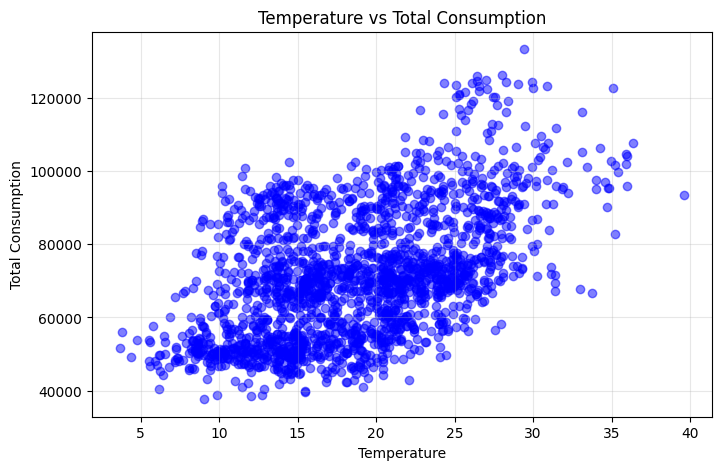

In [38]:
plt.figure(figsize=(8,5))
plt.scatter(sample_plot["Temperature"], sample_plot["Total_Consumption"], color="blue", alpha=0.5)
plt.title("Temperature vs Total Consumption")
plt.xlabel("Temperature")
plt.ylabel("Total Consumption")
plt.grid(True, alpha=0.3)
plt.show()

Temperature VS each Zone

In [39]:
for col in ["Zone1", "Zone2", "Zone3", "Total_Consumption"]:
    pearson_r, pearson_p = pearsonr(df_eda["Temperature"], df_eda[col])
    spearman_rho, spearman_p = spearmanr(df_eda["Temperature"], df_eda[col])
    print(col, "| Pearson:", round(pearson_r, 3), "| p:", pearson_p, "| Spearman:", round(spearman_rho, 3), "| p:", spearman_p)
    if pearson_p < 0.05:
        print("Reject H0: the correlation is statistically significant.\n")
    else:
        print("Fail to reject H0: the correlation is not statistically significant.\n")

Zone1 | Pearson: 0.44 | p: 0.0 | Spearman: 0.433 | p: 0.0
Reject H0: the correlation is statistically significant.

Zone2 | Pearson: 0.382 | p: 0.0 | Spearman: 0.379 | p: 0.0
Reject H0: the correlation is statistically significant.

Zone3 | Pearson: 0.49 | p: 0.0 | Spearman: 0.436 | p: 0.0
Reject H0: the correlation is statistically significant.

Total_Consumption | Pearson: 0.488 | p: 0.0 | Spearman: 0.469 | p: 0.0
Reject H0: the correlation is statistically significant.



##### 13. Data Preprocessing for Regression

In [40]:
df_model = df_eda.copy()
df_model.drop(["DateTime", "Consumption_Level"], axis=1, inplace=True)

print("Missing values:", df_model.isnull().sum().sum())
print("Duplicate rows:", df_model.duplicated().sum())
df_model.head()

Missing values: 0
Duplicate rows: 0


,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,Zone1,Zone2,Zone3,Hour,Month,DayOfMonth,DayOfWeek,Weekend,Total_Consumption
0,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,0,1,1,Sunday,1,70425.53544
1,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,0,1,1,Sunday,1,69320.84387
2,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,0,1,1,Sunday,1,67803.22193
3,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,0,1,1,Sunday,1,65489.23209
4,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,0,1,1,Sunday,1,63650.44627


DayOfWeek is a categorical column, so it is converted into numeric dummy columns.

In [41]:
df_model = pd.get_dummies(df_model, columns=["DayOfWeek"], drop_first=True, dtype=int)
df_model.head()

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,Zone1,Zone2,Zone3,Hour,Month,DayOfMonth,Weekend,Total_Consumption,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday
0,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,0,1,1,1,70425.53544,0,0,1,0,0,0
1,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,0,1,1,1,69320.84387,0,0,1,0,0,0
2,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,0,1,1,1,67803.22193,0,0,1,0,0,0
3,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,0,1,1,1,65489.23209,0,0,1,0,0,0
4,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,0,1,1,1,63650.44627,0,0,1,0,0,0


##### 14. Targets and Feature Selection
Four targets are predicted: Zone 1, Zone 2, Zone 3 and the combined total. The same input features are used for all of them.

In [42]:
targets = {
    "Zone 1": "Zone1",
    "Zone 2": "Zone2",
    "Zone 3": "Zone3",
    "Total (All Zones)": "Total_Consumption"
}
target_cols = list(targets.values())

print(df_model.corr()[target_cols].drop(target_cols).round(3))

                     Zone1  Zone2  Zone3  Total_Consumption
Temperature          0.440  0.382  0.490              0.488
Humidity            -0.287 -0.295 -0.233             -0.299
WindSpeed            0.167  0.146  0.279              0.222
GeneralDiffuseFlows  0.188  0.157  0.063              0.150
DiffuseFlows         0.080  0.045 -0.039              0.032
Hour                 0.728  0.663  0.454              0.680
Month               -0.005  0.320 -0.234              0.005
DayOfMonth           0.026  0.053 -0.005              0.025
Weekend             -0.073 -0.153  0.014             -0.072
DayOfWeek_Monday     0.015  0.019 -0.002              0.011
DayOfWeek_Saturday  -0.005 -0.036  0.011             -0.009
DayOfWeek_Sunday    -0.090 -0.162  0.007             -0.084
DayOfWeek_Thursday   0.028  0.063  0.001              0.031
DayOfWeek_Tuesday    0.021  0.037 -0.000              0.020
DayOfWeek_Wednesday  0.030  0.046  0.001              0.027


All features are kept as each one shows a relationship with consumption.

In [43]:
X = df_model.drop(target_cols, axis=1)
Y = df_model[target_cols]

print("Features:", X.columns.tolist())
print("X shape:", X.shape)
print("Y shape:", Y.shape)

Features: ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'Hour', 'Month', 'DayOfMonth', 'Weekend', 'DayOfWeek_Monday', 'DayOfWeek_Saturday', 'DayOfWeek_Sunday', 'DayOfWeek_Thursday', 'DayOfWeek_Tuesday', 'DayOfWeek_Wednesday']
X shape: (52416, 15)
Y shape: (52416, 4)


##### 15. Train-Test Split and Scaling

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 41932
Testing Data: 10484


Scaling is used for Ridge and Lasso regression.

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

##### 16. Training the Regression Models for Every Target

In [46]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

trained_models = {}
predictions = {}

for target_name, col in targets.items():
    y_train = Y_train[col]

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    ridge_model = Ridge(alpha=1.0)
    ridge_model.fit(X_train_scaled, y_train)

    lasso_model = Lasso(alpha=1.0)
    lasso_model.fit(X_train_scaled, y_train)

    dt_model = DecisionTreeRegressor(max_depth=8, random_state=42)
    dt_model.fit(X_train, y_train)

    rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
    rf_model.fit(X_train, y_train)

    trained_models[target_name] = {
        "Linear Regression": linear_model,
        "Ridge Regression": ridge_model,
        "Lasso Regression": lasso_model,
        "Decision Tree": dt_model,
        "Random Forest": rf_model
    }

    predictions[target_name] = {
        "Linear Regression": linear_model.predict(X_test),
        "Ridge Regression": ridge_model.predict(X_test_scaled),
        "Lasso Regression": lasso_model.predict(X_test_scaled),
        "Decision Tree": dt_model.predict(X_test),
        "Random Forest": rf_model.predict(X_test)
    }

    print(target_name, "- all 5 models trained")

Zone 1 - all 5 models trained
Zone 2 - all 5 models trained
Zone 3 - all 5 models trained
Total (All Zones) - all 5 models trained


In [47]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

trained_models = {}
predictions = {}

# 1. Simple Linear Regression
for target_name, col in targets.items():
    y_train = Y_train[col]

    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    y_pred_linear = linear_model.predict(X_test)

    trained_models[target_name] = {
        "Linear Regression": linear_model
    }
    predictions[target_name] = {
        "Linear Regression": y_pred_linear
    }

    print("\n==== Simple Linear Regression ====")
    print("Target:", target_name)
    print("Intercept:", linear_model.intercept_)
    print("Coefficients:", round(linear_model.coef_[0],3))



==== Simple Linear Regression ====
Target: Zone 1
Intercept: 17029.3464812074
Coefficients: 449.007

==== Simple Linear Regression ====
Target: Zone 2
Intercept: 12240.659893110165
Coefficients: 126.64

==== Simple Linear Regression ====
Target: Zone 3
Intercept: 5921.885683275721
Coefficients: 728.068

==== Simple Linear Regression ====
Target: Total (All Zones)
Intercept: 35191.89205759328
Coefficients: 1303.715


In [51]:
# 2. Ridge Regression
for target_name, col in targets.items():
    y_train = Y_train[col]

    ridge_model = Ridge(alpha=1.0)
    ridge_model.fit(X_train_scaled, y_train)

    y_pred_ridge = ridge_model.predict(X_test_scaled)

    trained_models[target_name]["Ridge Regression"] = ridge_model
    predictions[target_name]["Ridge Regression"] = y_pred_ridge

    print("\n==== Ridge Regression ====")
    print("Intercept",ridge_model.intercept_)
    print("Slope:",ridge_model.coef_[0])
    print("Equation:")
    print("y = ",round(ridge_model.intercept_,2), "+ (", round(ridge_model.coef_[0],4), ") * x")


==== Ridge Regression ====
Intercept 32332.038201139705
Slope: 2601.850301122926
Equation:
y =  32332.04 + ( 2601.8503 ) * x

==== Ridge Regression ====
Intercept 21033.585914135692
Slope: 733.8719107111752
Equation:
y =  21033.59 + ( 733.8719 ) * x

==== Ridge Regression ====
Intercept 17819.881742597132
Slope: 4218.866234806584
Equation:
y =  17819.88 + ( 4218.8662 ) * x

==== Ridge Regression ====
Intercept 71185.50585787254
Slope: 7554.588446640681
Equation:
y =  71185.51 + ( 7554.5884 ) * x


In [54]:
# 3. Lasso Regression
for target_name, col in targets.items():
    y_train = Y_train[col]

    lasso_model = Lasso(alpha=1.0)
    lasso_model.fit(X_train_scaled, y_train)

    y_pred_lasso = lasso_model.predict(X_test_scaled)

    trained_models[target_name]["Lasso Regression"] = lasso_model
    predictions[target_name]["Lasso Regression"] = y_pred_lasso

    print("\n====Lasso Regression====")
    print("Intercept",lasso_model.intercept_)
    print("Slope:",lasso_model.coef_[0])
    print("Equation:")
    print("y = ",round(lasso_model.intercept_,2), "+ (", round(lasso_model.coef_[0],4), ") * x")


====Lasso Regression====
Intercept 32332.038201139705
Slope: 2599.25956665833
Equation:
y =  32332.04 + ( 2599.2596 ) * x

====Lasso Regression====
Intercept 21033.585914135692
Slope: 734.3523147259496
Equation:
y =  21033.59 + ( 734.3523 ) * x

====Lasso Regression====
Intercept 17819.881742597132
Slope: 4216.616267148249
Equation:
y =  17819.88 + ( 4216.6163 ) * x

====Lasso Regression====
Intercept 71185.50585787254
Slope: 7553.2439802075905
Equation:
y =  71185.51 + ( 7553.244 ) * x


In [56]:
# 4. Decision Tree Regression
for target_name, col in targets.items():
    y_train = Y_train[col]

    dt_model = DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    )
    dt_model.fit(X_train, y_train)

    y_pred_dt = dt_model.predict(X_test)

    trained_models[target_name]["Decision Tree"] = dt_model
    predictions[target_name]["Decision Tree"] = y_pred_dt

    print("\n====Decision Tree Regression====")
    print("Intercept: ",dt_model.max_depth)
    print("Nodes: ",dt_model.tree_.node_count)


====Decision Tree Regression====
Intercept:  8
Nodes:  511

====Decision Tree Regression====
Intercept:  8
Nodes:  511

====Decision Tree Regression====
Intercept:  8
Nodes:  511

====Decision Tree Regression====
Intercept:  8
Nodes:  511


In [57]:
# 5. Random Forest Regression
for target_name, col in targets.items():
    y_train = Y_train[col]

    rf_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42
    )
    rf_model.fit(X_train, y_train)

    y_pred_rf = rf_model.predict(X_test)

    trained_models[target_name]["Random Forest"] = rf_model
    predictions[target_name]["Random Forest"] = y_pred_rf

    print("\n====Random Forest Regression====")
    print("Number of trees:",rf_model.n_estimators)

====Random Forest Regression====
Number of trees: 100
====Random Forest Regression====
Number of trees: 100
====Random Forest Regression====
Number of trees: 100
====Random Forest Regression====
Number of trees: 100


In [58]:

print("All 5 models trained for every target!")

All 5 models trained for every target!


##### 17. Model Evaluation and Comparison

In [59]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results = []

for target_name, col in targets.items():
    y_true = Y_test[col]
    for model_name, y_pred in predictions[target_name].items():
        mae = mean_absolute_error(y_true, y_pred)
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_true, y_pred)
        results.append([target_name, model_name, mae, mse, rmse, r2])

results_df = pd.DataFrame(results, columns=["Target", "Model", "MAE", "MSE", "RMSE", "R2"])

for target_name in targets:
    print("MODEL PERFORMANCE -", target_name.upper())
    print("=" * 70)
    print(results_df[results_df["Target"] == target_name].drop("Target", axis=1).round(4).to_string(index=False))
    print()

MODEL PERFORMANCE - ZONE 1
            Model       MAE          MSE      RMSE     R2
Linear Regression 3324.0891 1.755827e+07 4190.2591 0.6523
 Ridge Regression 3324.0952 1.755826e+07 4190.2577 0.6523
 Lasso Regression 3324.1704 1.755825e+07 4190.2569 0.6523
    Decision Tree 1461.1477 4.056780e+06 2014.1449 0.9197
    Random Forest 1105.5135 2.302099e+06 1517.2670 0.9544

MODEL PERFORMANCE - ZONE 2
            Model       MAE          MSE      RMSE     R2
Linear Regression 2569.9798 1.056240e+07 3249.9848 0.6086
 Ridge Regression 2569.9828 1.056239e+07 3249.9833 0.6087
 Lasso Regression 2569.9397 1.056195e+07 3249.9154 0.6087
    Decision Tree 1156.5870 2.396899e+06 1548.1923 0.9112
    Random Forest  810.9397 1.160353e+06 1077.1967 0.9570

MODEL PERFORMANCE - ZONE 3
            Model       MAE          MSE      RMSE     R2
Linear Regression 3279.3213 1.717436e+07 4144.1965 0.6061
 Ridge Regression 3279.3096 1.717436e+07 4144.1954 0.6061
 Lasso Regression 3279.1355 1.717380e+07 4144.1

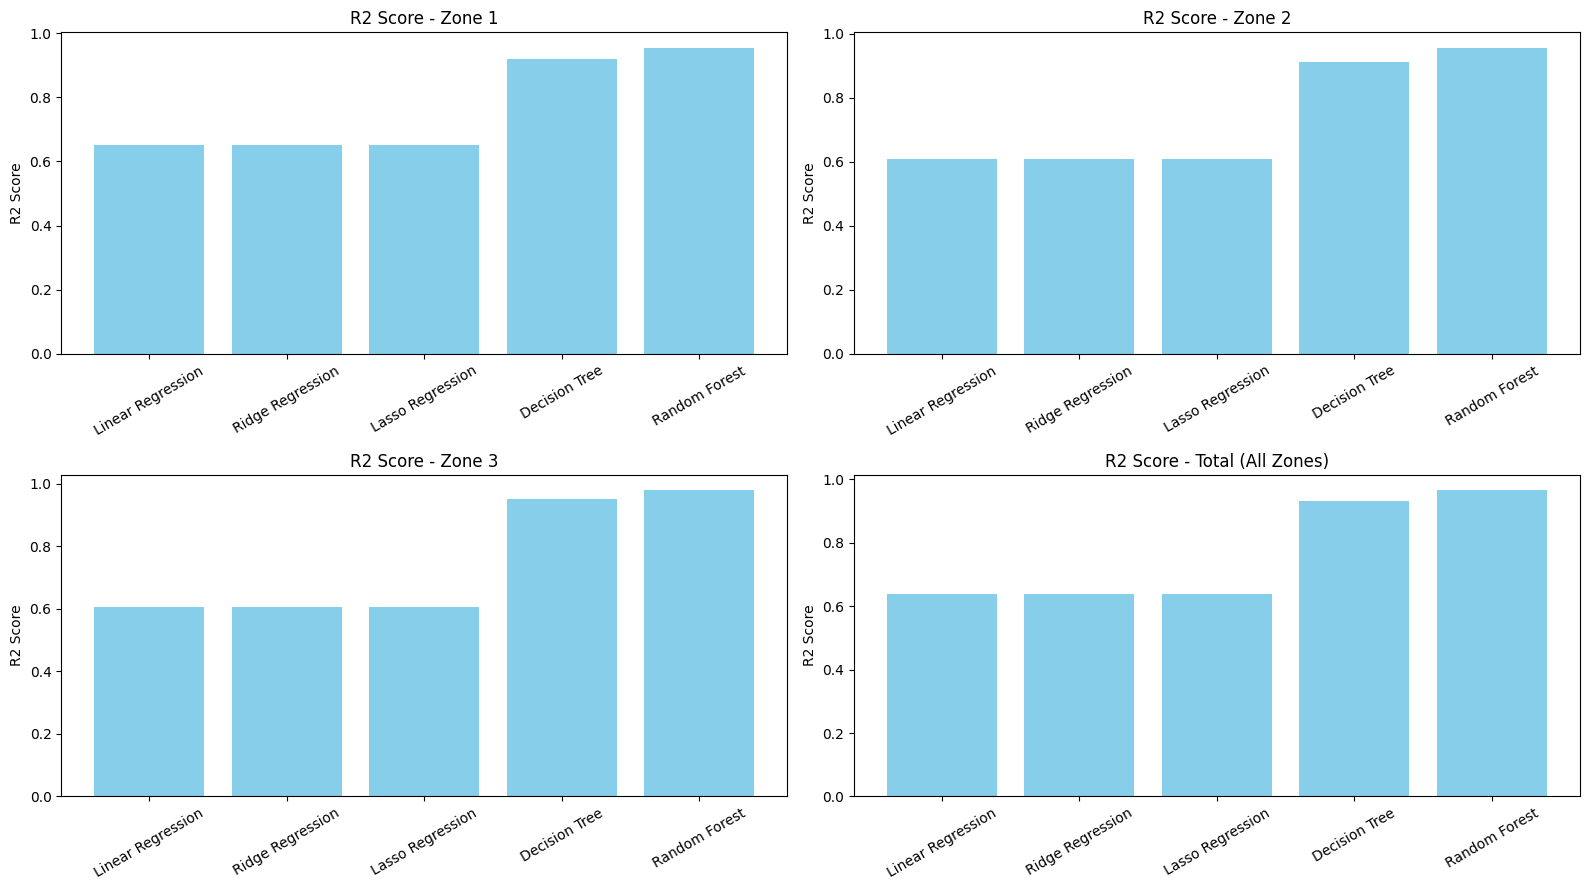

In [60]:
plt.figure(figsize=(16,9))
for i, target_name in enumerate(targets):
    sub = results_df[results_df["Target"] == target_name]
    plt.subplot(2,2,i+1)
    plt.bar(sub["Model"], sub["R2"], color="skyblue")
    plt.title("R2 Score - " + target_name)
    plt.ylabel("R2 Score")
    plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

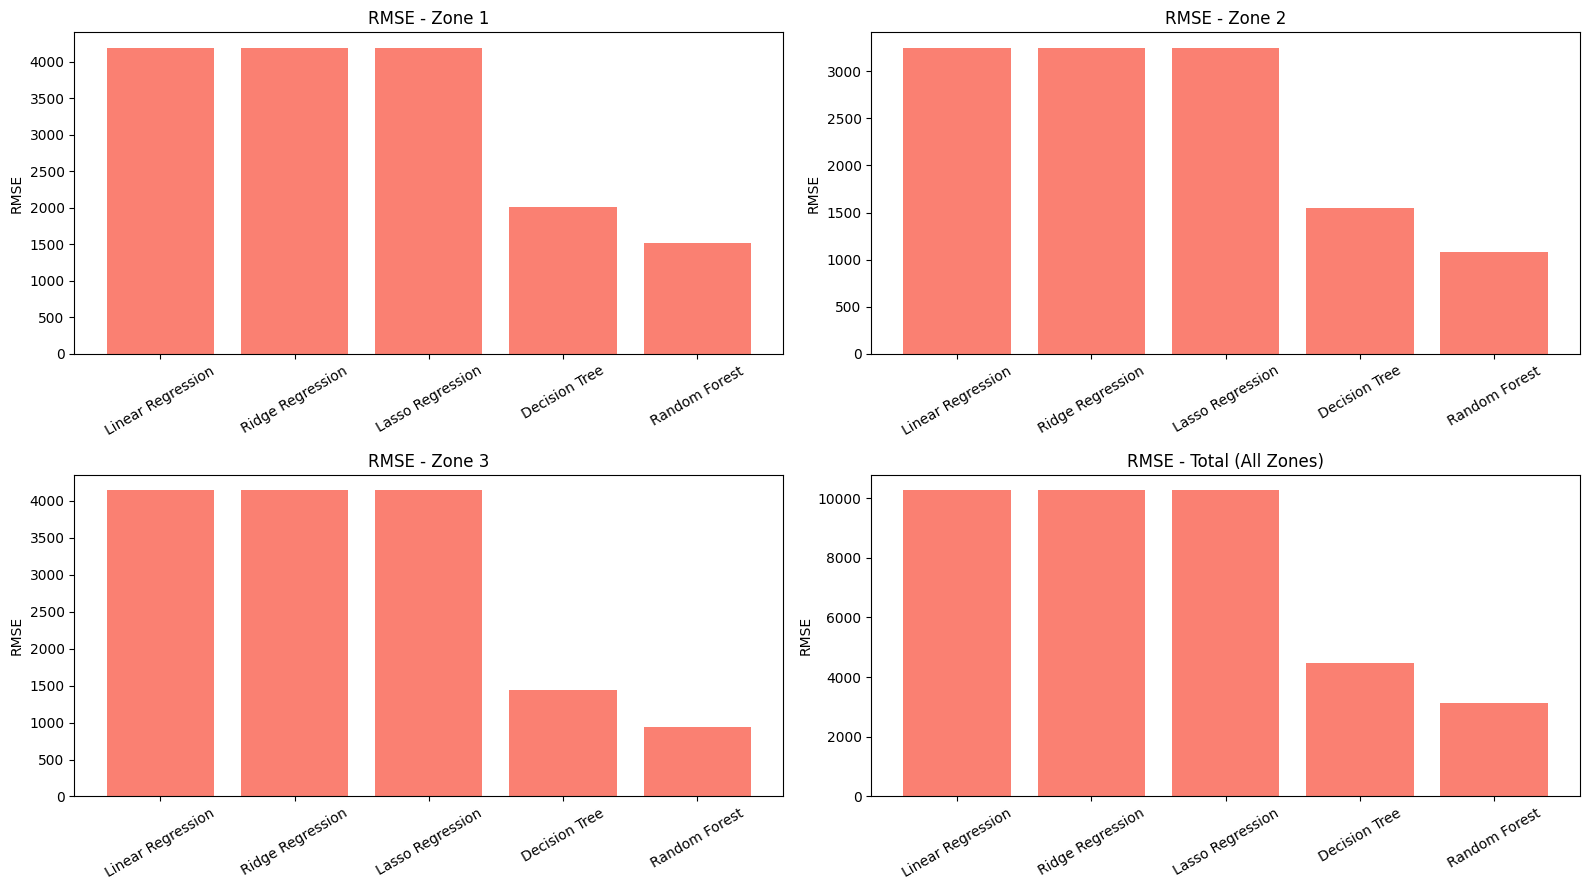

In [61]:
plt.figure(figsize=(16,9))
for i, target_name in enumerate(targets):
    sub = results_df[results_df["Target"] == target_name]
    plt.subplot(2,2,i+1)
    plt.bar(sub["Model"], sub["RMSE"], color="salmon")
    plt.title("RMSE - " + target_name)
    plt.ylabel("RMSE")
    plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

##### 18. Selecting the Best Model for Every Target

In [63]:
best_models = {}
best_model_names = {}

for target_name in targets:
    sub = results_df[results_df["Target"] == target_name]
    best_name = sub.loc[sub["R2"].idxmax(), "Model"]
    best_model_names[target_name] = best_name
    best_models[target_name] = trained_models[target_name][best_name]

best_summary = results_df.loc[results_df.groupby("Target")["R2"].idxmax()]
best_summary = best_summary.set_index("Target").loc[list(targets.keys())]
print("BEST MODEL FOR EACH TARGET")
print(best_summary.round(4).to_string())

BEST MODEL FOR EACH TARGET
                           Model        MAE           MSE       RMSE      R2
Target                                                                      
Zone 1             Random Forest  1105.5135  2.302099e+06  1517.2670  0.9544
Zone 2             Random Forest   810.9397  1.160353e+06  1077.1967  0.9570
Zone 3             Random Forest   656.9436  8.806994e+05   938.4558  0.9798
Total (All Zones)  Random Forest  2279.7814  9.811570e+06  3132.3426  0.9664


Actual vs Predicted (best model of each target)

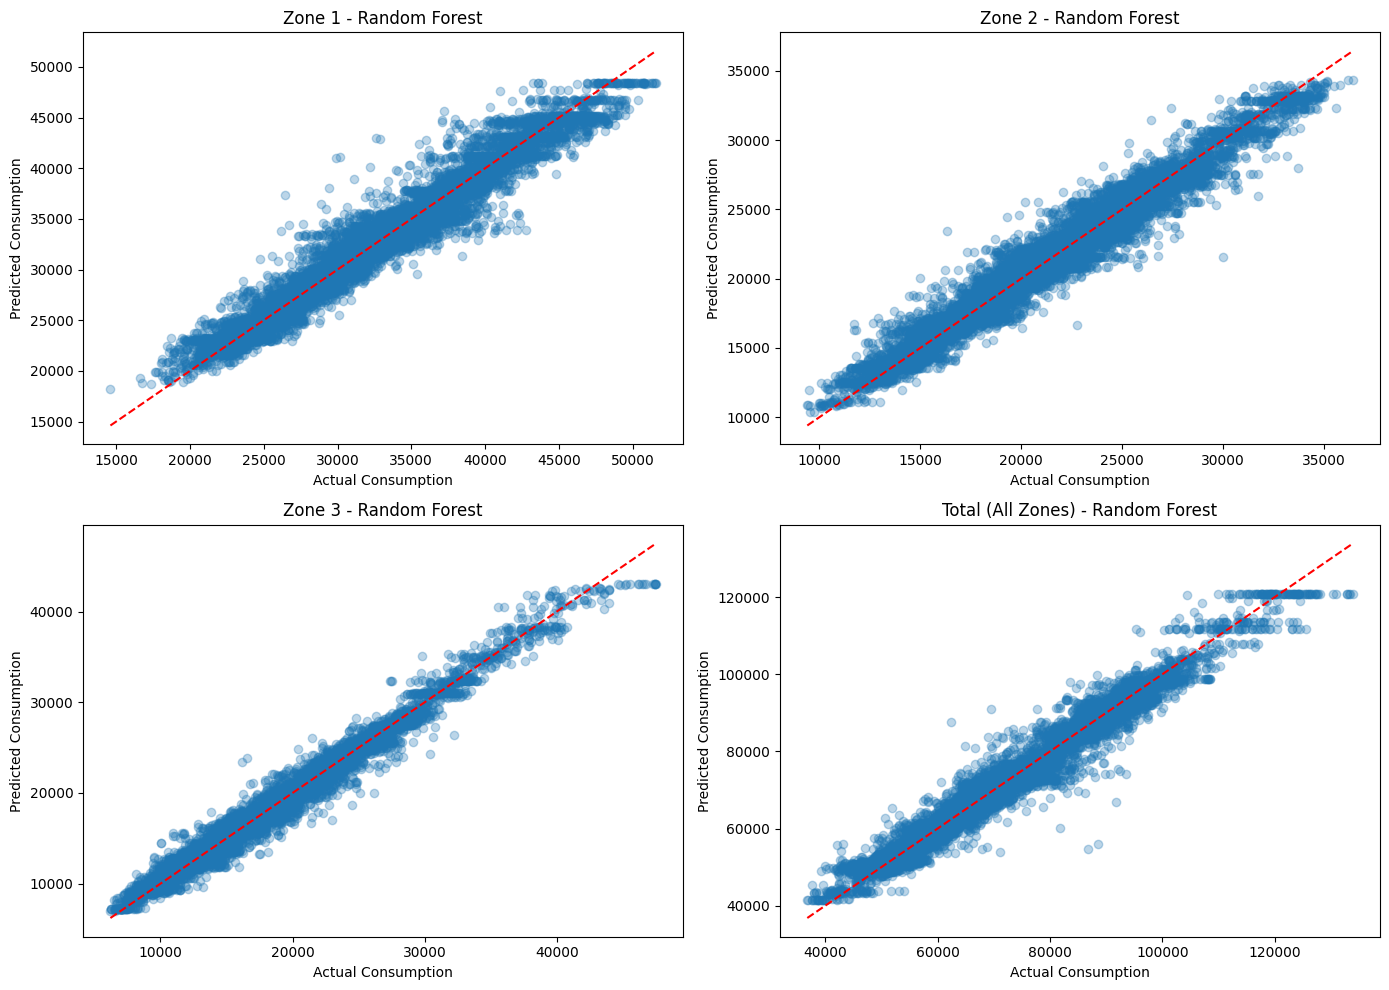

In [64]:
plt.figure(figsize=(14,10))
for i, target_name in enumerate(targets):
    y_true = Y_test[targets[target_name]]
    y_pred = predictions[target_name][best_model_names[target_name]]

    plt.subplot(2,2,i+1)
    plt.scatter(y_true, y_pred, alpha=0.3)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], color="red", linestyle="--")
    plt.xlabel("Actual Consumption")
    plt.ylabel("Predicted Consumption")
    plt.title(target_name + " - " + best_model_names[target_name])
plt.tight_layout()
plt.show()

First 150 test readings: actual vs predicted

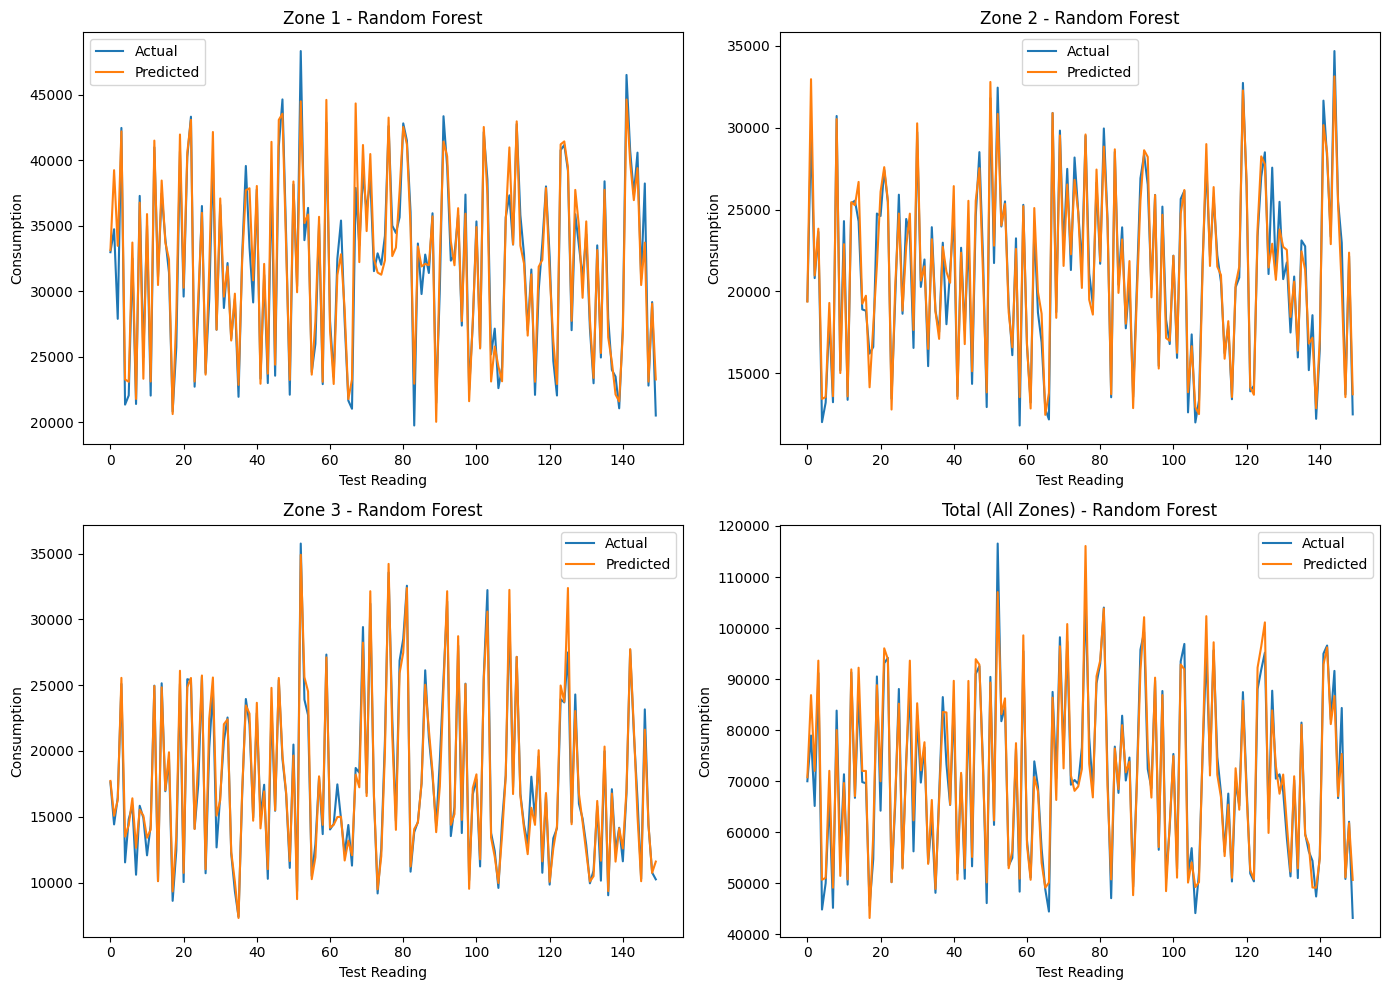

In [65]:
plt.figure(figsize=(14,10))
for i, target_name in enumerate(targets):
    y_true = Y_test[targets[target_name]].values[:150]
    y_pred = predictions[target_name][best_model_names[target_name]][:150]

    plt.subplot(2,2,i+1)
    plt.plot(y_true, label="Actual")
    plt.plot(y_pred, label="Predicted")
    plt.xlabel("Test Reading")
    plt.ylabel("Consumption")
    plt.title(target_name + " - " + best_model_names[target_name])
    plt.legend()
plt.tight_layout()
plt.show()

Zone-wise sum vs direct total prediction

In [66]:
zone_sum_pred = (predictions["Zone 1"][best_model_names["Zone 1"]]
                 + predictions["Zone 2"][best_model_names["Zone 2"]]
                 + predictions["Zone 3"][best_model_names["Zone 3"]])

y_total = Y_test["Total_Consumption"]
direct_pred = predictions["Total (All Zones)"][best_model_names["Total (All Zones)"]]

print("Sum of zone predictions -> R2:", round(r2_score(y_total, zone_sum_pred), 4), "| RMSE:", round(np.sqrt(mean_squared_error(y_total, zone_sum_pred)), 2))
print("Direct total prediction -> R2:", round(r2_score(y_total, direct_pred), 4), "| RMSE:", round(np.sqrt(mean_squared_error(y_total, direct_pred)), 2))

Sum of zone predictions -> R2: 0.9747 | RMSE: 2718.17
Direct total prediction -> R2: 0.9664 | RMSE: 3132.34


##### 19. Saving the Models and Preprocessing Objects

Ridge and Lasso were trained on scaled data, so model_info.pkl stores whether each selected model needs the scaler.

In [67]:
feature_columns = X.columns.tolist()

model_info = {}
for target_name in targets:
    name = best_model_names[target_name]
    r2_value = results_df[(results_df["Target"] == target_name) & (results_df["Model"] == name)]["R2"].values[0]
    model_info[target_name] = {
        "model_name": name,
        "use_scaler": name in ["Ridge Regression", "Lasso Regression"],
        "r2": float(r2_value)
    }

joblib.dump(best_models, "energy_models.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(feature_columns, "feature_columns.pkl")
joblib.dump(model_info, "model_info.pkl")

print("Saved: energy_models.pkl, scaler.pkl, feature_columns.pkl, model_info.pkl")
print(model_info)

Saved: energy_models.pkl, scaler.pkl, feature_columns.pkl, model_info.pkl
{'Zone 1': {'model_name': 'Random Forest', 'use_scaler': False, 'r2': 0.9544088131681591}, 'Zone 2': {'model_name': 'Random Forest', 'use_scaler': False, 'r2': 0.9570074603149639}, 'Zone 3': {'model_name': 'Random Forest', 'use_scaler': False, 'r2': 0.9798025691228209}, 'Total (All Zones)': {'model_name': 'Random Forest', 'use_scaler': False, 'r2': 0.9663609587149872}}


##### 20. Predicting on New Input

In [68]:
models = joblib.load("energy_models.pkl")
scaler = joblib.load("scaler.pkl")
feature_columns = joblib.load("feature_columns.pkl")
model_info = joblib.load("model_info.pkl")

new_input = pd.DataFrame([{
    "Temperature": 20.0,
    "Humidity": 60.0,
    "WindSpeed": 1.0,
    "GeneralDiffuseFlows": 100.0,
    "DiffuseFlows": 80.0,
    "Hour": 18,
    "Month": 7,
    "DayOfMonth": 15,
    "Weekend": 0,
    "DayOfWeek": "Monday"
}])

new_input = pd.get_dummies(new_input, columns=["DayOfWeek"], drop_first=True, dtype=int)
new_input = new_input.reindex(columns=feature_columns, fill_value=0)
new_input_scaled = scaler.transform(new_input)

print("PREDICTED CONSUMPTION")
for target_name, model in models.items():
    if model_info[target_name]["use_scaler"]:
        value = model.predict(new_input_scaled)[0]
    else:
        value = model.predict(new_input)[0]
    print(target_name, ":", round(value, 2), "(" + model_info[target_name]["model_name"] + ")")

PREDICTED CONSUMPTION
Zone 1 : 37807.15 (Random Forest)
Zone 2 : 29106.91 (Random Forest)
Zone 3 : 31584.18 (Random Forest)
Total (All Zones) : 84913.33 (Random Forest)


## 21. Conclusion
- Electricity consumption was predicted separately for Zone 1, Zone 2, Zone 3 and for the combined total.
- Five regression models were compared for each target using MAE, MSE, RMSE and R².
- The model with the highest R² was selected for each target and saved with the scaler and feature columns for use in the Streamlit app.